# Practice 09 — CNN Pipeline

**Goal:** run one image pipeline with two models, so the scores differ by the model, not the data.

| Model | Weights |
|:---|:---|
| VGG-11 | trained from scratch |
| ResNet18 | pretrained on ImageNet, last block and classifier fine-tuned |

| Step | What it produces |
|:---|:---|
| Data | train / validation / test split, augmented, wrapped in `DataLoader` |
| `train` / `evaluate` | the epoch loop and the no-grad evaluation, written once |
| Models | two `nn.Module`s returning logits |
| Diagnostics | learning curves, final test score, confusion matrix |

- Data → CIFAR-10: 32×32 colour photographs, 10 classes, resized to 96×96

---
## Step 0. Imports and Setup

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['axes.unicode_minus'] = False

# a GPU is worth having here; on a CPU-only machine .to(device) is a no-op and the run takes hours
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


---
## Step 1. Data

| Set | Size | Source | Transform |
|:---|:---|:---|:---|
| Train | 10000 | training split | resize, crop, flip, normalize |
| Validation | 2000 | training split | resize, normalize |
| Test | 2000 | test split | resize, normalize |

- Random crop and flip → training only; evaluation has to be deterministic
- ImageNet normalization for both models → the statistics ResNet18 was pretrained with, one mean and one std per channel

- `Resize(96)` → five halvings of 32×32 would end at 1×1; from 96 the last block still has a 3×3 map
- A transform is bound to a dataset object → the training split is loaded twice, augmented for train and plain for validation; `Subset(dataset, range(...))` picks the rows
- Batch size 64 for training, 128 for evaluation → no gradients to store when evaluating

In [2]:
# published ImageNet statistics, the ones the pretrained weights were fitted under
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

transform_train = transforms.Compose([
    transforms.Resize(96),
    transforms.RandomCrop(96, padding=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

transform_eval = transforms.Compose([
    transforms.Resize(96),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

cifar_train_aug = torchvision.datasets.CIFAR10(
    root='./data', train=True,  download=True, transform=transform_train)
cifar_train_plain = torchvision.datasets.CIFAR10(
    root='./data', train=True,  download=True, transform=transform_eval)
cifar_test = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_eval)

# the validation images come out of the training split, so the test split stays untouched until the end
train_set = Subset(cifar_train_aug, range(10000))
val_set   = Subset(cifar_train_plain, range(10000, 12000))
test_set  = Subset(cifar_test, range(2000))

train_loader = DataLoader(train_set, batch_size=64,  shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=128, shuffle=False)

class_names = cifar_test.classes
y_test = np.array(cifar_test.targets[:2000])

print(f'train: {len(train_set)}, val: {len(val_set)}, test: {len(test_set)}')
print(f'batches per epoch - train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}')

X_batch, Y_batch = next(iter(train_loader))
print(f'one batch - X {tuple(X_batch.shape)} {X_batch.dtype}, Y {tuple(Y_batch.shape)} {Y_batch.dtype}')

train: 10000, val: 2000, test: 2000
batches per epoch - train: 157, val: 16, test: 16
one batch - X (64, 3, 96, 96) torch.float32, Y (64,) torch.int64


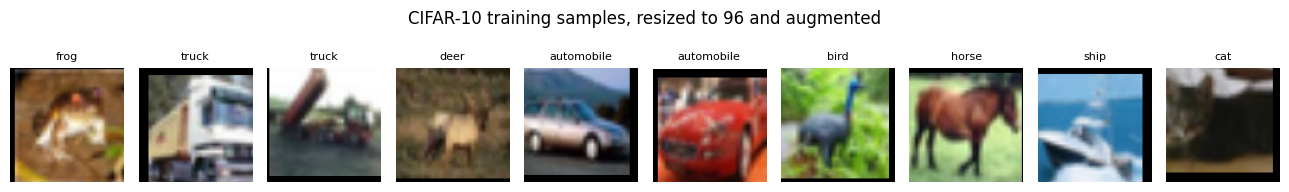

In [3]:
# turns a normalized (C, H, W) tensor back into an (H, W, C) array that imshow can display
def unnormalize(image_tensor):
    image = image_tensor.permute(1, 2, 0).numpy()
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(image, 0, 1)


fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for i in range(10):
    image, label = train_set[i]
    axes[i].imshow(unnormalize(image))
    axes[i].set_title(class_names[label], fontsize=8)
    axes[i].axis('off')
plt.suptitle('CIFAR-10 training samples, resized to 96 and augmented', y=1.05)
plt.tight_layout()
plt.show()

---
## Step 2. `train` and `evaluate`

| Function | Does | Returns |
|:---|:---|:---|
| `evaluate(model, loader, device)` | one pass, gradients off | `(loss, accuracy, y_pred)` |
| `train(model, train_loader, val_loader, optimizer, epochs, device)` | epoch loop, `evaluate` on `val_loader` each epoch | `(train_losses, train_accs, val_losses, val_accs)` |

- Neither names a model or dataset → the second model reuses both unchanged
- Loss $J$ = `nn.CrossEntropyLoss`, built inside both functions → the returned loss is its mean per epoch
- Only `val_loader` inside `train` → the test set must not steer the choice of model

In [4]:
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    loss_sum, correct, count = 0.0, 0, 0
    preds = []
    with torch.no_grad():
        for X_batch, Y_batch in loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)
            loss = criterion(output, Y_batch)
            y_hat = output.argmax(1)
            loss_sum += loss.item()
            correct += (y_hat == Y_batch).sum().item()
            count += len(Y_batch)
            preds.append(y_hat.cpu())      # .numpy() below needs CPU tensors

    y_pred = torch.cat(preds).numpy()
    return loss_sum / len(loader), correct / count, y_pred   # mean of the batch means, accuracy per sample

In [5]:
def train(model, train_loader, val_loader, optimizer, epochs, device):
    criterion = nn.CrossEntropyLoss()
    train_losses, train_accs, val_losses, val_accs = [], [], [], []
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        for X_batch, Y_batch in train_loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)               # logits, (batch, 10)
            loss = criterion(output, Y_batch)

            optimizer.zero_grad()                 # clear the accumulated gradients
            loss.backward()                       # autograd computes the gradients
            optimizer.step()                      # the optimizer updates the parameters

            loss_sum += loss.item()
            correct += (output.argmax(1) == Y_batch).sum().item()
            count += len(Y_batch)

        train_loss = loss_sum / len(train_loader)     # mean of the batch means
        train_acc = correct / count
        val_loss, val_acc, _ = evaluate(model, val_loader, device)

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        print(f'  Epoch {epoch:2d}/{epochs}  '
              f'train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  '
              f'train_acc={train_acc:.4f}  val_acc={val_acc:.4f}')
    return train_losses, train_accs, val_losses, val_accs

- Shared by both models → `epochs`, `momentum`; the learning rate is set per model (Step 5)

In [6]:
epochs   = 15
momentum = 0.9

print(f'loss     : {nn.CrossEntropyLoss()}')
print(f'epochs   : {epochs}')
print(f'momentum : {momentum}')

loss     : CrossEntropyLoss()
epochs   : 15
momentum : 0.9


---
## Step 3. VGGNet from Scratch

- Only 3×3 convolutions, stride 1 → depth is the only design variable
- Two stacked 3×3 layers see the 5×5 window of one 5×5 layer → fewer weights, one more non-linearity
- VGG-11 = 8 convolutions in 5 blocks + 3 linear layers with dropout 0.5 between them; each block ends in a pool that halves the resolution
- Convolutions start from He (Kaiming normal) initialization → `nn.init.kaiming_normal_`

- Two departures from the 2014 paper → the deep stack trains in one run on this data; the convolutional stack is unchanged

| Here | In the paper |
|:---|:---|
| `BatchNorm2d` after every convolution | no normalization; deeper configurations were started from a shallower trained one |
| Classifier 512-512-10 | 4096-4096-1000, which on ten classes at 96×96 would hold most of the parameters |

In [7]:
class VGG11(nn.Module):
    def __init__(self):
        super().__init__()
        # block 1 - one convolution, 96 -> 48
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 2 - one convolution, 48 -> 24
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 3 - two convolutions, 24 -> 12
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 4 - two convolutions, 12 -> 6
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 5 - two convolutions, 6 -> 3
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.MaxPool2d(2))

        self.classifier = nn.Sequential(
            nn.Linear(512 * 3 * 3, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 10))

        # He initialization, matched to the ReLU that follows each convolution
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = x.flatten(1)          # keep the batch axis, flatten the rest
        z = self.classifier(x)    # logits; the softmax is applied inside the loss
        return z


torch.manual_seed(42)
model_vgg = VGG11().to(device)
n_params_vgg = sum(p.numel() for p in model_vgg.parameters())
print(f'VGG-11 parameters: {n_params_vgg:,}')

VGG-11 parameters: 11,853,578


- The shape after each block → where `512 * 3 * 3` in the first linear layer comes from

In [8]:
x = torch.randn(1, 3, 96, 96).to(device)
print(f'input          : {tuple(x.shape)}')

x = model_vgg.block1(x)
print(f'after block1   : {tuple(x.shape)}')

x = model_vgg.block2(x)
print(f'after block2   : {tuple(x.shape)}')

x = model_vgg.block3(x)
print(f'after block3   : {tuple(x.shape)}')

x = model_vgg.block4(x)
print(f'after block4   : {tuple(x.shape)}')

x = model_vgg.block5(x)
print(f'after block5   : {tuple(x.shape)}')

print(f'after flatten  : {tuple(x.flatten(1).shape)}')

input          : (1, 3, 96, 96)
after block1   : (1, 64, 48, 48)
after block2   : (1, 128, 24, 24)
after block3   : (1, 256, 12, 12)
after block4   : (1, 512, 6, 6)
after block5   : (1, 512, 3, 3)
after flatten  : (1, 4608)


In [9]:
optimizer_vgg = torch.optim.SGD(model_vgg.parameters(), lr=0.01, momentum=momentum)

torch.manual_seed(42)   # train_loader shuffles and augments from the same state for both models
print(f'Training VGG-11 from scratch on {device} ...')
train_losses_vgg, train_accs_vgg, val_losses_vgg, val_accs_vgg = train(
    model_vgg, train_loader, val_loader, optimizer_vgg, epochs=epochs, device=device)
print()
print(f'final val_acc={val_accs_vgg[-1]:.4f}')

Training VGG-11 from scratch on cuda ...


  Epoch  1/15  train_loss=1.9829  val_loss=1.7355  train_acc=0.2400  val_acc=0.3190


  Epoch  2/15  train_loss=1.7368  val_loss=1.5161  train_acc=0.3390  val_acc=0.4345


  Epoch  3/15  train_loss=1.6229  val_loss=1.5541  train_acc=0.3914  val_acc=0.4310


  Epoch  4/15  train_loss=1.5381  val_loss=1.4642  train_acc=0.4294  val_acc=0.4735


...

  Epoch 11/15  train_loss=1.0509  val_loss=0.9898  train_acc=0.6300  val_acc=0.6740


  Epoch 12/15  train_loss=0.9955  val_loss=1.0540  train_acc=0.6573  val_acc=0.6265


  Epoch 13/15  train_loss=0.9578  val_loss=0.9849  train_acc=0.6681  val_acc=0.6675


  Epoch 14/15  train_loss=0.9286  val_loss=1.0554  train_acc=0.6785  val_acc=0.6375


  Epoch 15/15  train_loss=0.8823  val_loss=0.9627  train_acc=0.7000  val_acc=0.6770

final val_acc=0.6770


---
## Step 4. Pretrained ResNet18

| Part | `requires_grad` | Why |
|:---|:---|:---|
| `conv1` … `layer3` | `False` | general visual features, kept |
| `layer4` | `True` | specific to the original task |
| `fc` → a new `Linear(512, 10)` | `True`, by construction | 1000 ImageNet classes → 10 |

- torchvision's ResNet18 → `conv1`, `bn1`, `relu`, `maxpool`, `layer1` … `layer4` (the residual blocks), `avgpool`, `fc`
- The optimizer gets only the trainable parameters → frozen weights are never updated
- `model.train()` still updates the BatchNorm running statistics in the frozen blocks → they adapt to these images

In [10]:
from torchvision.models import resnet18, ResNet18_Weights

torch.manual_seed(42)
model_resnet = resnet18(weights=ResNet18_Weights.DEFAULT)

for parameter in model_resnet.parameters():
    parameter.requires_grad = False
for parameter in model_resnet.layer4.parameters():
    parameter.requires_grad = True

model_resnet.fc = nn.Linear(model_resnet.fc.in_features, 10)   # 1000 ImageNet classes -> 10
model_resnet = model_resnet.to(device)

n_params_resnet = sum(p.numel() for p in model_resnet.parameters())
n_params_trainable = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
trainable_fraction = n_params_trainable / n_params_resnet
print(f'total     parameters: {n_params_resnet:,}')
print(f'trainable parameters: {n_params_trainable:,}  ({trainable_fraction:.1%})')

# the classifier is random at this point, so the accuracy should sit near chance level, 10%
_, acc_val_before, _ = evaluate(model_resnet, val_loader, device)
print(f'val_acc before fine-tuning: {acc_val_before:.4f}')

total     parameters: 11,181,642
trainable parameters: 8,398,858  (75.1%)


val_acc before fine-tuning: 0.0795


- `layer4` + `fc` = 75.1% of the parameters → the last block is most of the network
- 0.08 before fine-tuning → chance level (0.10)

In [11]:
trainable = [p for p in model_resnet.parameters() if p.requires_grad]
optimizer_resnet = torch.optim.SGD(trainable, lr=0.001, momentum=momentum)

torch.manual_seed(42)   # train_loader shuffles and augments from the same state for both models
print(f'Fine-tuning ResNet18 on {device} ...')
train_losses_resnet, train_accs_resnet, val_losses_resnet, val_accs_resnet = train(
    model_resnet, train_loader, val_loader, optimizer_resnet, epochs=epochs, device=device)
print()
print(f'final val_acc={val_accs_resnet[-1]:.4f}')

Fine-tuning ResNet18 on cuda ...


  Epoch  1/15  train_loss=1.3505  val_loss=0.8595  train_acc=0.5411  val_acc=0.7070


  Epoch  2/15  train_loss=0.7626  val_loss=0.6879  train_acc=0.7374  val_acc=0.7615


  Epoch  3/15  train_loss=0.6328  val_loss=0.6045  train_acc=0.7794  val_acc=0.7950


  Epoch  4/15  train_loss=0.5487  val_loss=0.5682  train_acc=0.8125  val_acc=0.8045


...

  Epoch 11/15  train_loss=0.3113  val_loss=0.4801  train_acc=0.8934  val_acc=0.8410


  Epoch 12/15  train_loss=0.2897  val_loss=0.4599  train_acc=0.9010  val_acc=0.8430


  Epoch 13/15  train_loss=0.2652  val_loss=0.4678  train_acc=0.9094  val_acc=0.8385


  Epoch 14/15  train_loss=0.2525  val_loss=0.4604  train_acc=0.9126  val_acc=0.8435


  Epoch 15/15  train_loss=0.2301  val_loss=0.4787  train_acc=0.9216  val_acc=0.8425

final val_acc=0.8425


---
## Step 5. Comparison

| | VGG-11 | ResNet18 |
|:---|:---|:---|
| Model | 11 weight layers, from scratch | pretrained, `layer4` and `fc` trained |
| Learning rate | 0.01 | 0.001 |

- **Fixed** → loaders, input size, augmentation, batch size, epochs, SGD with momentum 0.9, seeds
- The learning rate goes with the pretraining → at 0.01 the pretrained weights would move too far from where they started
- Architecture, pretraining and learning rate all differ → the gap cannot be pinned on one of them; the fixed items only make the comparison fair

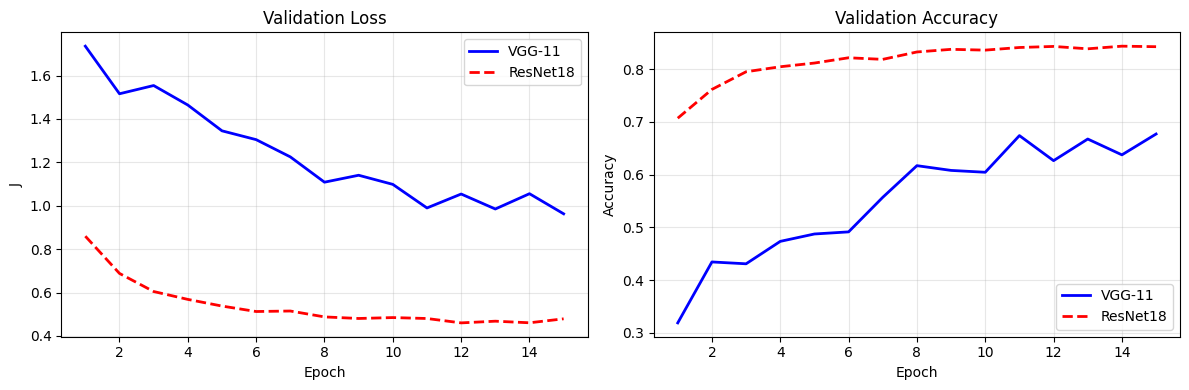

final val_acc - vgg: 0.6770, resnet: 0.8425


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, epochs + 1)

axes[0].plot(epochs_range, val_losses_vgg, 'b-',  linewidth=2, label='VGG-11')
axes[0].plot(epochs_range, val_losses_resnet, 'r--', linewidth=2, label='ResNet18')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('J')
axes[0].set_title('Validation Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, val_accs_vgg, 'b-',  linewidth=2, label='VGG-11')
axes[1].plot(epochs_range, val_accs_resnet, 'r--', linewidth=2, label='ResNet18')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'final val_acc - vgg: {val_accs_vgg[-1]:.4f}, resnet: {val_accs_resnet[-1]:.4f}')

- VGG-11 → 0.32 to 0.68, swinging by ±0.04 between epochs; train accuracy 0.70 ≈ validation: undertrained, not overfitted — eleven weight layers on 10000 images need more epochs or more data
- ResNet18 → 0.71 after one epoch, flat near 0.84 from epoch 9
- The numbers move from run to run (GPU arithmetic, random augmentation) → read the pattern, not the third decimal

---
## Step 6. Final Test Evaluation

- The choice between the models was made on validation → read the test split now, once per model

In [13]:
loss_test_vgg, acc_test_vgg, y_pred_vgg = evaluate(model_vgg, test_loader, device)
loss_test_resnet, acc_test_resnet, y_pred_resnet = evaluate(model_resnet, test_loader, device)

print(f'VGG-11    test_loss={loss_test_vgg:.4f}  test_acc={acc_test_vgg:.4f}')
print(f'ResNet18  test_loss={loss_test_resnet:.4f}  test_acc={acc_test_resnet:.4f}')

VGG-11    test_loss=0.9442  test_acc=0.6720
ResNet18  test_loss=0.4761  test_acc=0.8380


- Test 0.67 vs. 0.84, validation 0.68 vs. 0.84 → the validation split was a fair guide

---
## Step 7. Where the Errors Are

- Accuracy counts the errors, it does not locate them
- `shuffle=False` → `y_pred_resnet` is aligned with `test_set`, so each index points back at its image
- Confusion matrix → off-diagonal entries name the class pairs being confused

misclassified: 324 of 2000 test images


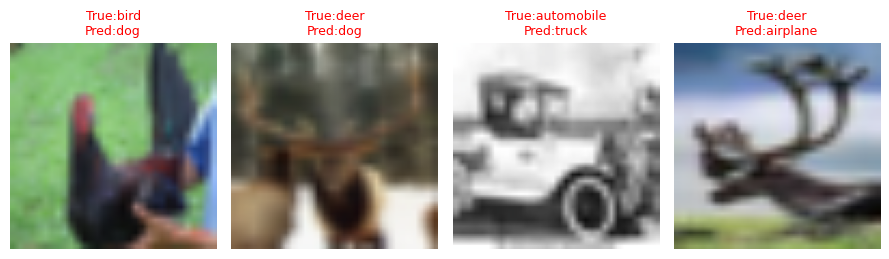

In [14]:
wrong_index = np.where(y_pred_resnet != y_test)[0]
print(f'misclassified: {len(wrong_index)} of {len(y_test)} test images')

fig, axes = plt.subplots(1, 4, figsize=(9, 2.8))
for i in range(4):
    index = wrong_index[i]
    image, _ = test_set[index]
    axes[i].imshow(unnormalize(image))
    axes[i].set_title(f'True:{class_names[y_test[index]]}\nPred:{class_names[y_pred_resnet[index]]}',
                      color='red', fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

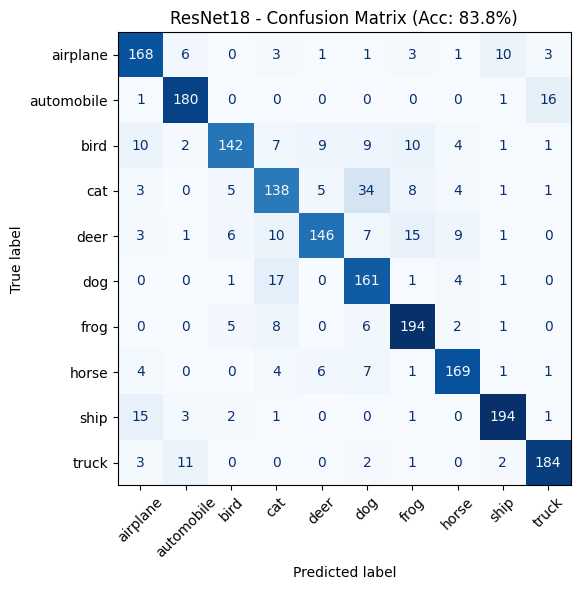

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_resnet), display_labels=class_names)
display_matrix.plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
ax.set_title(f'ResNet18 - Confusion Matrix (Acc: {acc_test_resnet:.1%})')
plt.tight_layout()
plt.show()

- 324 errors in 2000 → the largest off-diagonal entry: 34 cats read as dogs, then 17 dogs as cats and 16 automobiles as trucks

---
## Summary

- Pipeline = loaders, `train` / `evaluate`, a model, diagnostics → swapping the model left the other three untouched
- Same 15 epochs → test accuracy 0.67 for VGG-11 from scratch, 0.84 for the fine-tuned ResNet18
- Models compared on validation → test split read once, afterwards

---
## Exercises

1. Unfreeze `layer3` as well — what does the trainable fraction become, and does accuracy follow?
2. Drop the augmentation from `transform_train`, retrain VGG-11 — which curve moves, train or validation?
3. Swap `resnet18` for `resnet34` or `mobilenet_v2` (head: `classifier[1]`) — compare accuracy against the parameter count.
4. Load your own photographs (`data/my_photos/<class>/<file>.jpg`) with `torchvision.datasets.ImageFolder` — fine-tune the same ResNet18.

In [16]:
# Write your code here